# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga

In [3]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"

# Cargamos el CSV en un DataFrame
df = pd.read_csv(DATA_PATH)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [6]:
# Forma del dataset (filas, columnas)
print("Forma:", df.shape)

# Tipos de datos de cada columna
print("\nTipos de datos:")
print(df.dtypes)

# Valores nulos por columna
print("\nTotal de valores nulos:", df.isna().sum().sum())

# Filas duplicadas
print("Filas duplicadas:", df.duplicated().sum())



Forma: (178, 14)

Tipos de datos:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object

Total de valores nulos: 0
Filas duplicadas: 0


## 2. Split train/test

In [7]:
# Separamos 80 % entrenamiento y 20 % prueba.
# stratify mantiene la misma proporción de clases en ambos conjuntos.
TEST_SIZE = 0.2

train_df, test_df = train_test_split(
    df,
    test_size=TEST_SIZE,
    stratify=df["target"],
    random_state=RANDOM_STATE,
)

In [8]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

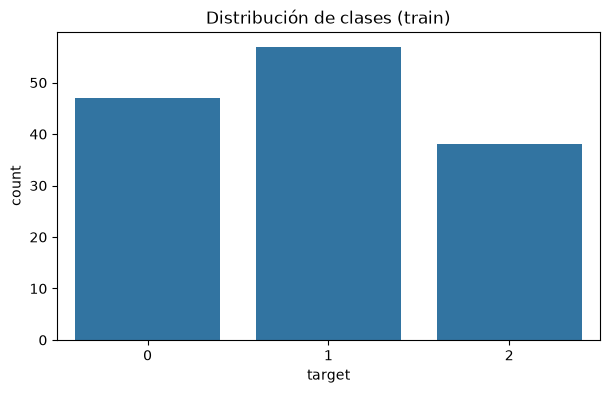

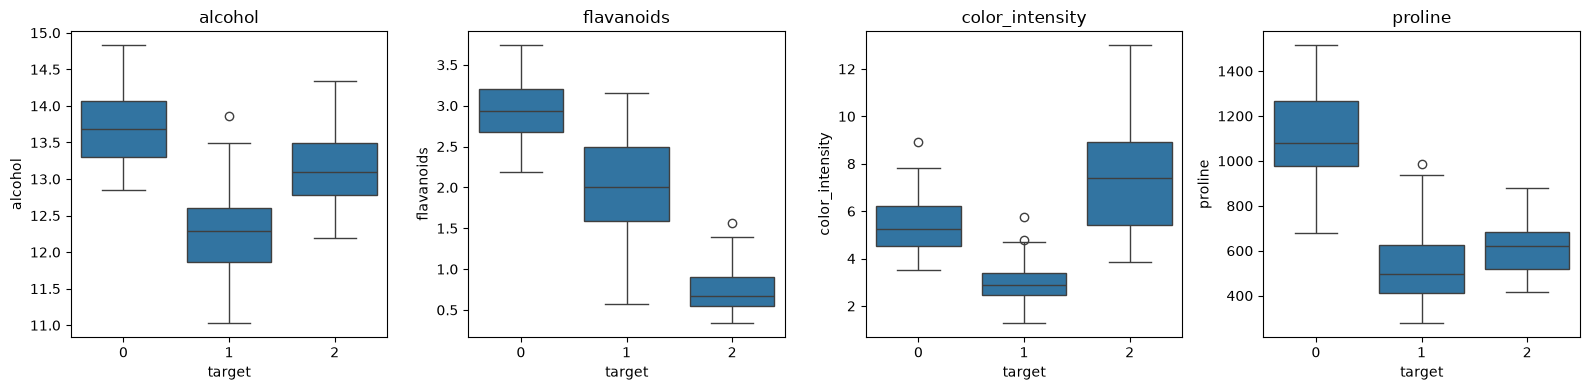

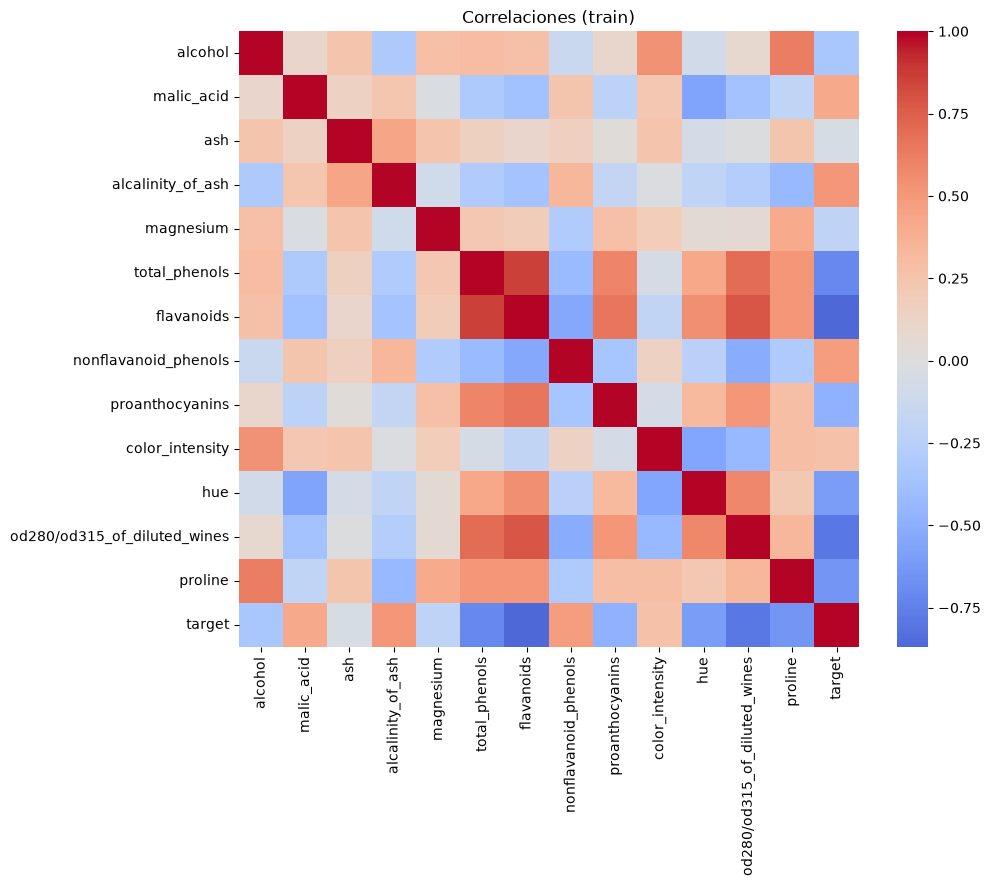

flavanoids                      0.870180
od280/od315_of_diluted_wines    0.784280
total_phenols                   0.713752
proline                         0.638823
hue                             0.605732
alcalinity_of_ash               0.507562
proanthocyanins                 0.481488
nonflavanoid_phenols            0.476767
malic_acid                      0.418279
alcohol                         0.331843
color_intensity                 0.268592
magnesium                       0.207569
ash                             0.044951
Name: target, dtype: float64


In [9]:
# A partir de aquí SOLO usamos train_df (el test no se mira)

# 1) Distribución de clases en entrenamiento
plt.figure()
sns.countplot(x="target", data=train_df)
plt.title("Distribución de clases (train)")
plt.show()

# 2) Boxplots de algunas variables por clase
variables = ["alcohol", "flavanoids", "color_intensity", "proline"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, variables):
    sns.boxplot(x="target", y=col, data=train_df, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# 3) Mapa de correlaciones entre variables
plt.figure(figsize=(10, 8))
sns.heatmap(train_df.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlaciones (train)")
plt.show()

# Correlación de cada variable con el target (en valor absoluto)
print(train_df.corr()["target"].drop("target").abs().sort_values(ascending=False))

In [10]:
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

data_contract = {
    "target": "target",
    "features": [col for col in df.columns if col != "target"],
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
}

with open(ARTIFACTS_DIR / "data_contract.json", "w", encoding="utf-8") as f:
    json.dump(data_contract, f, indent=2)

print(json.dumps(data_contract, indent=2))

{
  "target": "target",
  "features": [
    "alcohol",
    "malic_acid",
    "ash",
    "alcalinity_of_ash",
    "magnesium",
    "total_phenols",
    "flavanoids",
    "nonflavanoid_phenols",
    "proanthocyanins",
    "color_intensity",
    "hue",
    "od280/od315_of_diluted_wines",
    "proline"
  ],
  "random_state": 42,
  "test_size": 0.2
}


In [11]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.
